# Fee effects on Polymarket market quality

Reproduces the analysis from the durable pipeline outputs in `data/export/` (`scripts/40–43`),
answering two research questions about the taker fee, plus its incidence.

**RQ1 — does the fee change price *quality*?** Two dimensions, both **no measurable change**:
- *single-market calibration* — Brier reliability ≈ 0 in both eras (V1/V2 gaps are sharpness/mix);
- *cross-market consistency* — the negRisk arbitrage-band "widening" is a liquidity/placebo artifact.

**RQ2 — who keeps linked markets consistent, and how does the fee change their incentives?** A
**distinct, concentrated, persistent** group of arbitrageurs closes the negRisk band — and the fee
turns their gross edge into a **net loss** (net margin +42.8 → −106.5 bps, pre → post).

**How they relate:** the negRisk band `|S−1|` is the shared object — RQ1 asks about its *level* (the
fee doesn't widen it), RQ2 about its *agents* (the fee taxes them). Central tension: **the fee does
not degrade market quality, yet it makes the correction that maintains that quality unprofitable.**

**Incidence (supporting):** the fee is regressive — longshot/small traders pay up to ~40× favorites/whales.

In [1]:
import sys, json
from pathlib import Path
import pandas as pd
sys.path.insert(0, str(Path.cwd().parent / "src"))
from intellifi import config, fee_calibration as fc, fee_figures as F, correction
pd.set_option("display.width", 200)
EXPORT = config.DATA_DIR / "export"
%matplotlib inline

## RQ1 — Forecast calibration under the fee
Brier decomposition by era: *reliability* = mis-calibration, *resolution* = sharpness.

In [2]:
era = pd.read_csv(EXPORT / "calibration_era_decomposition.csv"); era

,era,horizon,n,brier,reliability,resolution,uncertainty,base_rate
0,v1 all,p_1h,633087,0.0870,0.0001,0.1479,0.2350,0.378
1,v1 oracle,p_1h,180093,0.0699,0.0001,0.1777,0.2476,0.451
2,v2 fee,p_1h,817460,0.0495,0.0002,0.1734,0.2229,0.336
3,v1 all,p_last,789268,0.0426,0.0001,0.1974,0.2401,0.401
4,v1 oracle,p_last,311243,0.0052,0.0000,0.2440,0.2492,0.471
5,v2 fee,p_last,1221498,0.0126,0.0003,0.2248,0.2372,0.387


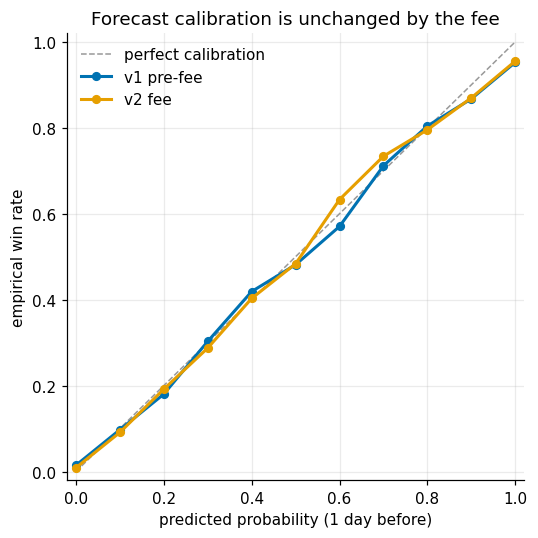

In [3]:
F.fig_reliability()

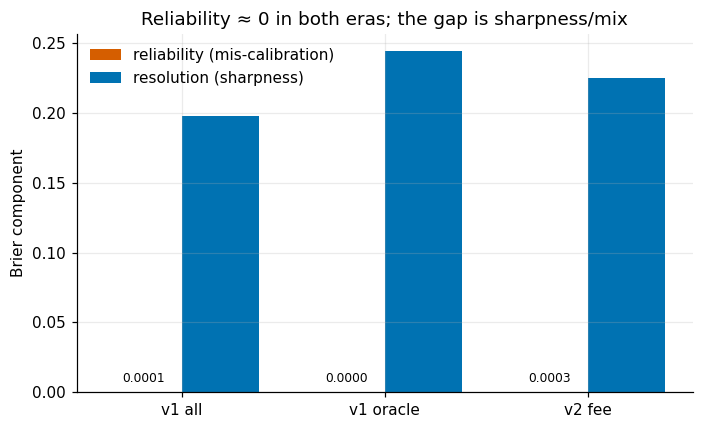

In [4]:
F.fig_brier_decomp()

Reliability ≈ 0.000 in **every** cell (V1 and V2): near-perfectly calibrated in both regimes. The lower V2 Brier is *resolution* (sharpness) — a more-predictable market mix, not better forecasts.

### negRisk arbitrage-band widening — rejected artifact

In [5]:
print(json.dumps(json.loads((EXPORT / "negrisk_band_audit.json").read_text()), indent=2))

{
  "raw_fee_minus_nofee": 0.0282,
  "cleanest_treated_crypto_gap_ci": [
    0.0095,
    0.0039,
    0.0159
  ],
  "never_treated_placebo_gap_ci": [
    0.0513,
    0.0441,
    0.0594
  ],
  "verdict": "artifact: crypto ~0, placebo large -> not a fee effect"
}


## Fee incidence — regressive
Assumption-free effective rate (actual `fee_raw`) from the full tape.

In [6]:
print((EXPORT / "incidence_overall.json").read_text())

{
  "eff_rate_pct": 1.117,
  "total_fee": 156314418.0,
  "total_notional": 13989759876.0,
  "frac_takers_any_fee": 0.941,
  "n_takers": 1141274.0
}


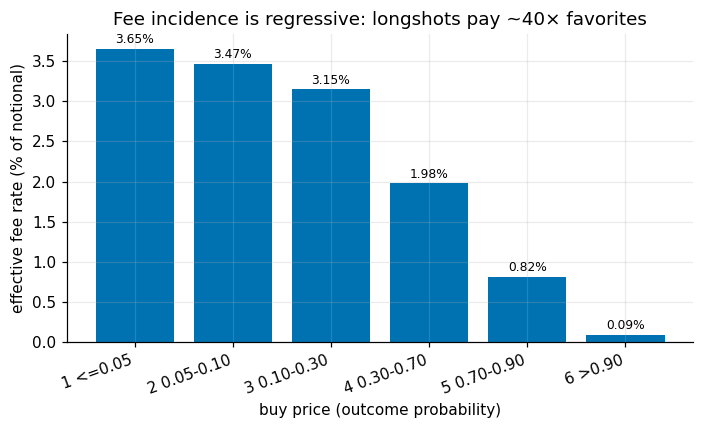

In [7]:
F.fig_incidence_price()

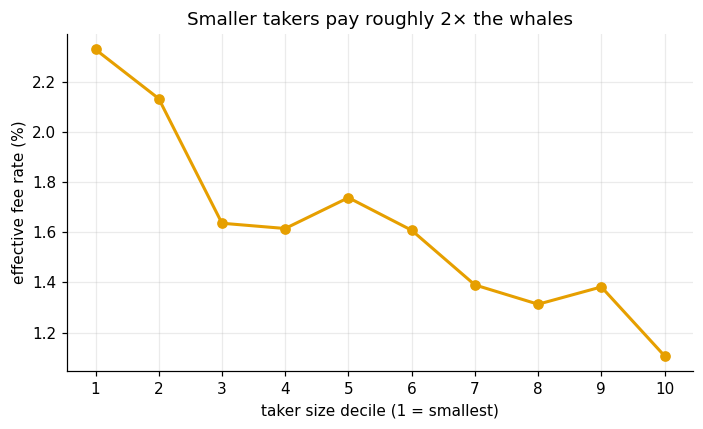

In [8]:
F.fig_incidence_size()

## RQ2 — Who corrects price inconsistencies, and does the fee affect it?

In [9]:
rq2 = correction.analyze(str(EXPORT / "rq2_v2")); print(json.dumps(rq2, indent=2))

{
  "concentration": {
    "n_correctors": 31487,
    "gini": 0.985,
    "top10_pct": 15.3,
    "top100_pct": 32.6
  },
  "distinctness": {
    "vol": {
      "spearman_ep_wins": 0.262,
      "top100_overlap": 0.09
    },
    "pnl": {
      "spearman_ep_wins": -0.028,
      "top100_overlap": 0.03
    },
    "fee_paid": {
      "spearman_ep_wins": 0.269,
      "top100_overlap": 0.09
    },
    "n_trades": {
      "spearman_ep_wins": 0.351,
      "top100_overlap": 0.56
    }
  },
  "profitability": {
    "correctors_gross_pnl": 2444274,
    "correctors_fees": 9989750,
    "correctors_net": -7545477,
    "frac_net_profitable": 0.32,
    "correctors_vol": 708466737,
    "span_days": 125,
    "gross_margin_bps": 34.5,
    "fee_drag_bps": 141.0,
    "net_margin_bps": -106.5,
    "all_takers_gross_pnl": -28169192,
    "all_takers_net": -52437620
  },
  "generalism": {
    "top50_median_families": 577,
    "correctors_in_ge5_families": 5390
  },
  "persistence": {
    "spearman_h1_h2": 0.49,
 

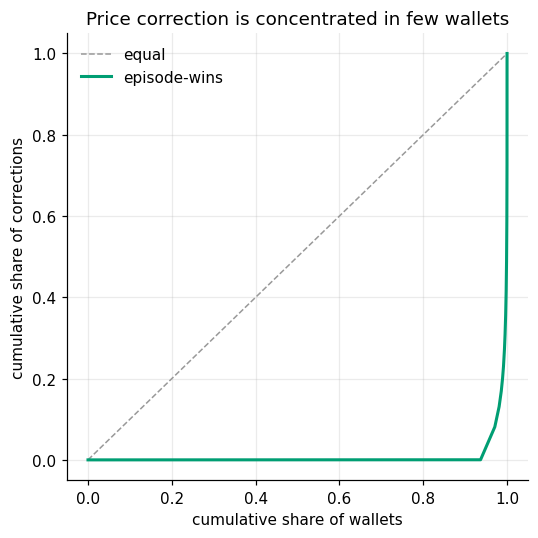

In [10]:
F.fig_rq2_concentration()

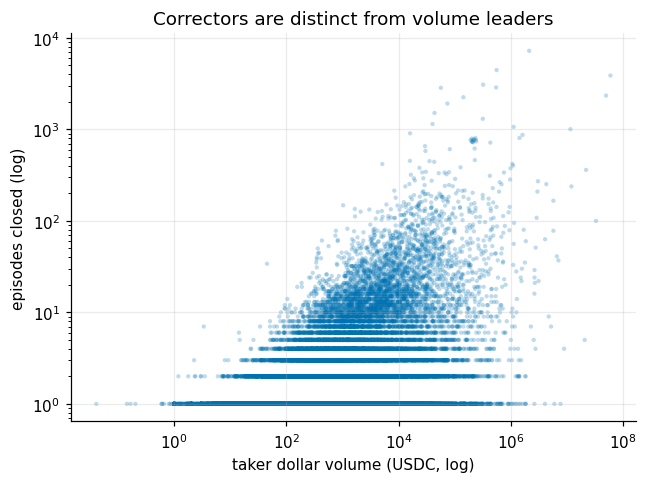

In [11]:
F.fig_rq2_distinctness()

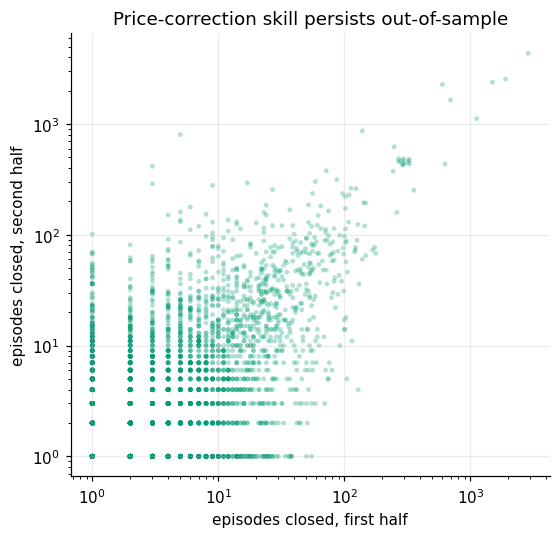

In [12]:
F.fig_rq2_persistence()

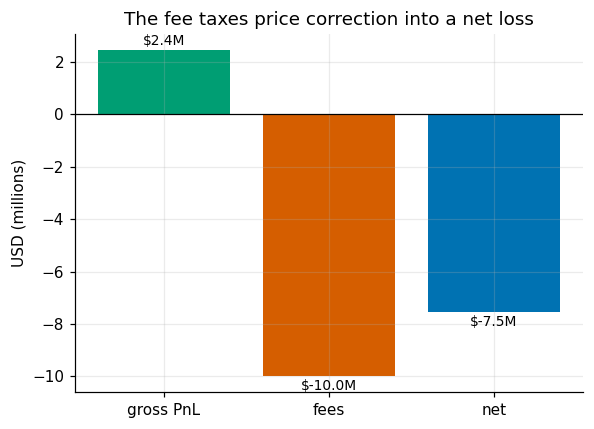

In [13]:
F.fig_rq2_profitability(rq2)

Correctors are a **distinct, concentrated, persistent** group (not the volume/profit leaders), with genuine gross edge — but the taker fee turns them **net-negative**.

## Pre- vs post-fee: the economics of price correction

In [14]:
rq2_v1 = correction.analyze(str(EXPORT / "rq2_v1"))
pre, post = rq2_v1["profitability"], rq2["profitability"]
pd.DataFrame({"pre-fee (V1)": pre, "fee (V2)": post})

,pre-fee (V1),fee (V2)
correctors_gross_pnl,2.429186e+07,2.444274e+06
correctors_fees,1.715345e+07,9.989750e+06
correctors_net,7.138413e+06,-7.545477e+06
frac_net_profitable,3.400000e-01,3.200000e-01
correctors_vol,1.666234e+09,7.084667e+08
span_days,8.430000e+02,1.250000e+02
gross_margin_bps,1.458000e+02,3.450000e+01
fee_drag_bps,1.029000e+02,1.410000e+02
net_margin_bps,4.280000e+01,-1.065000e+02
all_takers_gross_pnl,-3.349298e+07,-2.816919e+07


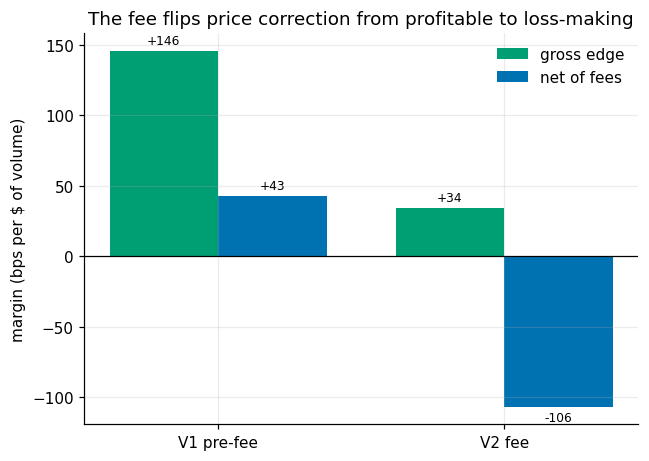

In [15]:
F.fig_rq2_prepost(rq2_v1, rq2)